In [1]:
# learns the user's AC routine from the data instead of hand written rules like R1, R2 and R3 from Assignment 2
# given the room and the time, what setting does the user want (off, 16C, 19C, 20C or 21C), then we compare it with the rules
# run 00_preprocessing first, it makes data_1min.csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

In [2]:
# load the per minute data, ac_setting as a string so 'off' and '16C' stay labels
m = pd.read_csv('data_1min.csv', parse_dates=['pc_time'], index_col='pc_time', dtype={'ac_setting': str})
m['ac_setting'].value_counts()

ac_setting
off    3098
20C    2071
16C    1500
19C     742
Name: count, dtype: int64

In [3]:
# 17 and 18 only show up for a few seconds while the remote goes down from 21 to 16, not a real choice so drop them
m = m[~m['ac_setting'].isin(['17C', '18C'])].copy()
m['ac_setting'].value_counts()

ac_setting
off    3098
20C    2071
16C    1500
19C     742
Name: count, dtype: int64

In [4]:
# hour as sin/cos so 23:00 and 00:00 end up close to each other
m['hour_sin'] = np.sin(2 * np.pi * m['hour'] / 24)
m['hour_cos'] = np.cos(2 * np.pi * m['hour'] / 24)

# room now, whether it's heating up or cooling down, whether someone's there, and the time
# the current AC state is left out on purpose, otherwise the model would just copy it
FEATURES = ['temp_c', 'humidity_pct', 'temp_change_5m', 'temp_30m_ago',
            'mic_median_5m', 'occupied', 'hour_sin', 'hour_cos', 'weekday']
data = m.dropna(subset=FEATURES + ['ac_setting'])
X = data[FEATURES]
y = data['ac_setting']
print(len(data), 'rows')

7381 rows


In [5]:
# same as the forecast, no shuffling, first 80% train and last 20% test
split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print('train:', X_train.index.min(), 'to', X_train.index.max())
print('test :', X_test.index.min(), 'to', X_test.index.max())
print(y_test.value_counts().to_dict())

train: 2026-11-05 20:59:00 to 2026-11-09 23:22:00
test : 2026-11-09 23:23:00 to 2026-11-10 23:59:00
{'off': 726, '20C': 516, '16C': 205, '19C': 30}


In [6]:
# balanced class weights since 'off' shows up way more than the other settings
# confidence is the highest probability out of all the settings
model = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)
confidence = model.predict_proba(X_test).max(axis=1)

In [7]:
# accuracy, macro F1 and the per setting report
print('Accuracy :', round(accuracy_score(y_test, pred), 3))
print('F1 (macro):', round(f1_score(y_test, pred, average='macro'), 3))
print()
print(classification_report(y_test, pred, zero_division=0))

Accuracy : 0.618
F1 (macro): 0.485

              precision    recall  f1-score   support

         16C       0.83      1.00      0.91       205
         19C       0.03      0.57      0.06        30
         20C       0.00      0.00      0.00       516
         off       1.00      0.95      0.97       726

    accuracy                           0.62      1477
   macro avg       0.47      0.63      0.49      1477
weighted avg       0.61      0.62      0.61      1477



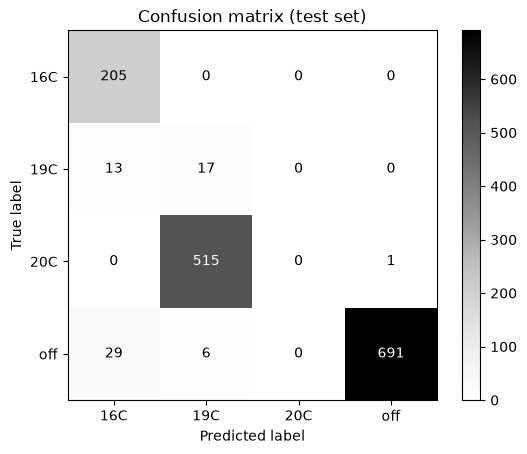

In [8]:
# which settings get mixed up with which
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Greys')
plt.title('Confusion matrix (test set)')
plt.show()

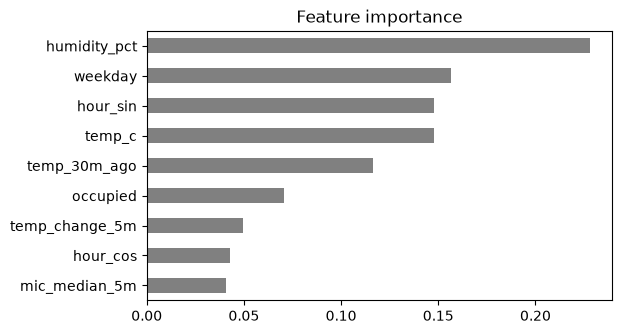

In [9]:
# which features the model leans on the most
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind='barh', color='gray', figsize=(6, 3.5), title='Feature importance')
plt.show()

In [10]:
# Talos should only act when the model is sure, so check how accurate it is above 80% confidence
sure = confidence >= 0.8
print(f'{sure.mean():.0%} of the test minutes have confidence >= 80%')
print('accuracy on those:', round(accuracy_score(y_test[sure], pred[sure]), 3))

84% of the test minutes have confidence >= 80%
accuracy on those: 0.711


In [11]:
# replays a simple version of R1, R2 and R3 minute by minute (R4 and R5 left out to keep it simple)
def replay_rules(d):
    state = 'off'
    last_change = None
    occ_since = d.index[0]
    prev_occ = d['occupied'].iloc[0]
    out = []
    for t, r in d.iterrows():
        # how long the room has been occupied or empty
        if r['occupied'] != prev_occ:
            occ_since, prev_occ = t, r['occupied']
        held = (t - occ_since).total_seconds() / 60
        sp = None if state == 'off' else int(state[:-1])
        # R1: AC on and empty for 15 min -> off
        if sp and not r['occupied'] and held >= 15:
            state, last_change = 'off', t
        # R2: AC off, occupied 2 min, temp >= 26 -> 16
        elif sp is None and r['occupied'] and held >= 2 and r['temp_c'] >= 26:
            state, last_change = '16C', t
        # R3: night, room cooled, humidity ok, 30 min since last change -> raise
        elif sp and sp < 21 and (t.hour >= 23 or t.hour < 3) and r['humidity_pct'] <= 66 \
                and r['temp_c'] <= 20.9 + 0.32 * (sp - 16) + 0.2 \
                and (last_change is None or (t - last_change).total_seconds() >= 1800):
            state, last_change = str(19 if sp < 19 else sp + 1) + 'C', t
        out.append(state)
    return pd.Series(out, index=d.index)

# see how often the rules end up at the same setting as the user on the same test data
test = data.iloc[split:]
rule_pred = replay_rules(test)

pd.DataFrame([
    {'method': 'Assignment 2 rules (R1-R3)', 'accuracy': round(accuracy_score(y_test, rule_pred), 3),
     'F1 (macro)': round(f1_score(y_test, rule_pred, average='macro'), 3)},
    {'method': 'Random Forest', 'accuracy': round(accuracy_score(y_test, pred), 3),
     'F1 (macro)': round(f1_score(y_test, pred, average='macro'), 3)},
])

,method,accuracy,F1 (macro)
0,Assignment 2 rules (R1-R3),0.483,0.231
1,Random Forest,0.618,0.485


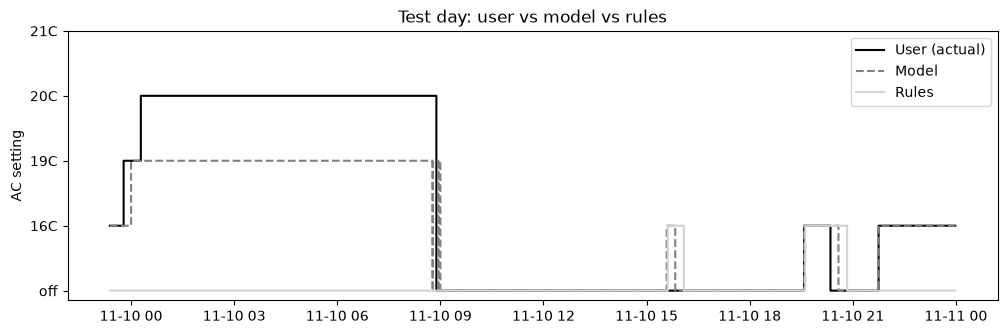

In [12]:
# user vs model vs rules over the test days
fig, ax = plt.subplots(figsize=(12, 3.5))
order = ['off', '16C', '19C', '20C', '21C']
to_num = {k: i for i, k in enumerate(order)}
ax.step(y_test.index, y_test.map(to_num), where='post', color='black', label='User (actual)')
ax.step(y_test.index, pd.Series(pred, index=y_test.index).map(to_num), where='post', color='gray', linestyle='--', label='Model')
ax.step(y_test.index, rule_pred.map(to_num), where='post', color='lightgray', label='Rules')
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_ylabel('AC setting')
ax.legend()
plt.title('Test day: user vs model vs rules')
plt.show()

In [13]:
# save the model so service.py can load it without training again
# it predicts every minute from talos/readings and sends ac_recommendation and confidence on talos/predictions
# the board only sends the IR command when the confidence is at least 80% for 3 minutes in a row and it's different from the current AC state
joblib.dump({'model': model, 'features': FEATURES}, 'ac_recommender_model.pkl')
print('saved ac_recommender_model.pkl')

saved ac_recommender_model.pkl


In [14]:
# try it with one situation, evening, the room is hot and someone's there
hour = 20
now = pd.DataFrame([{
    'temp_c': 28.0, 'humidity_pct': 72, 'temp_change_5m': 0.1, 'temp_30m_ago': 27.8,
    'mic_median_5m': 45000, 'occupied': 1,
    'hour_sin': np.sin(2 * np.pi * hour / 24), 'hour_cos': np.cos(2 * np.pi * hour / 24), 'weekday': 2,
}])
p = model.predict_proba(now[FEATURES])[0]
best = model.classes_[p.argmax()]
print('Recommended AC setting:', best, f'(confidence {p.max():.0%})')

Recommended AC setting: 16C (confidence 73%)
